In [3]:
# ==========================================
# SUPPLYCHAINIQ - EXPLORATORY DATA ANALYSIS
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Locate project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load cleaned dataset
file_path = (
    PROJECT_ROOT / "data" / "processed" /
    "supplychain_cleaned.csv"
)

clean_df = pd.read_csv(file_path)

# Convert date columns
date_columns = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for col in date_columns:
    clean_df[col] = pd.to_datetime(clean_df[col])

print("SupplyChainIQ dataset loaded successfully!")
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])

SupplyChainIQ dataset loaded successfully!
Rows: 180519
Columns: 50


In [4]:
total_orders = clean_df["Order Id"].nunique()
total_customers = clean_df["Customer Id"].nunique()
total_order_items = clean_df["Order Item Id"].nunique()

total_sales = clean_df["Sales"].sum()
average_sales = clean_df["Sales"].mean()
total_profit = clean_df["Benefit per order"].sum()

print("========== SUPPLYCHAINIQ KPI SUMMARY ==========")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Order Items: {total_order_items:,}")
print(f"Total Sales: {total_sales:,.2f}")
print(f"Average Sales per Item: {average_sales:,.2f}")
print(f"Total Recorded Benefit: {total_profit:,.2f}")
print("================================================")

========== SUPPLYCHAINIQ KPI SUMMARY ==========
Total Orders: 65,752
Total Customers: 20,652
Total Order Items: 180,519
Total Sales: 36,784,735.01
Average Sales per Item: 203.77
Total Recorded Benefit: 3,966,902.97


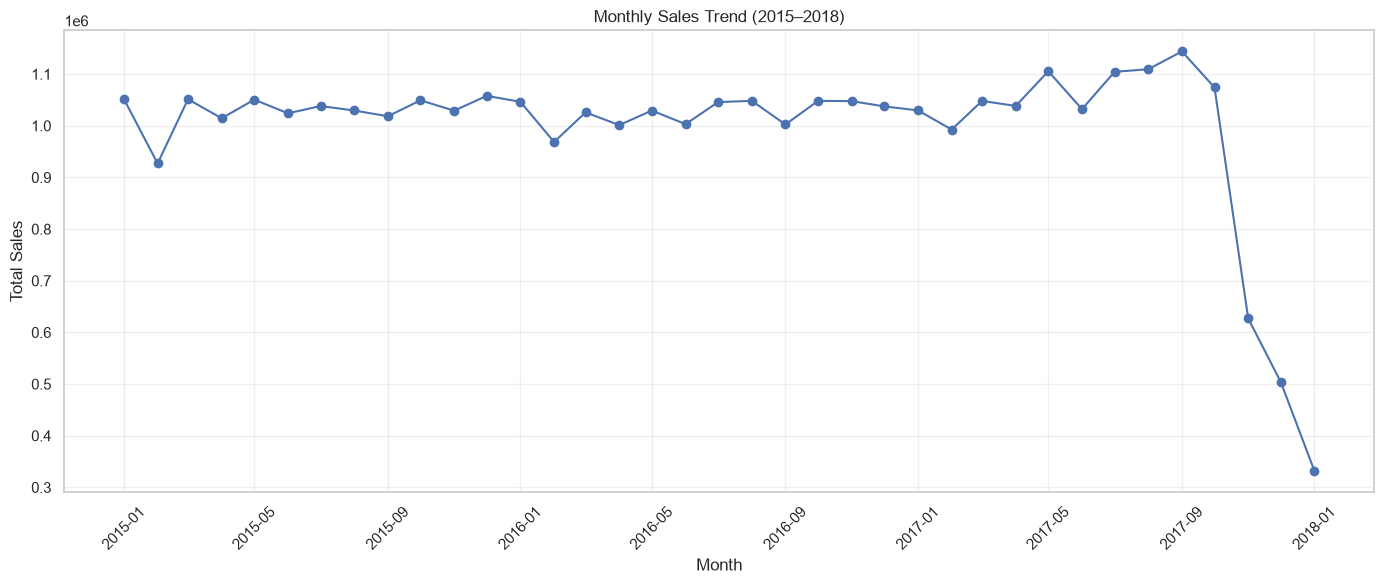

In [5]:
monthly_sales = (
    clean_df.groupby(
        clean_df["order date (DateOrders)"].dt.to_period("M")
    )["Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend (2015–2018)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,Year,Total Sales
0,2015,12340831.43
1,2016,12303817.32
2,2017,11808436.14
3,2018,331650.12


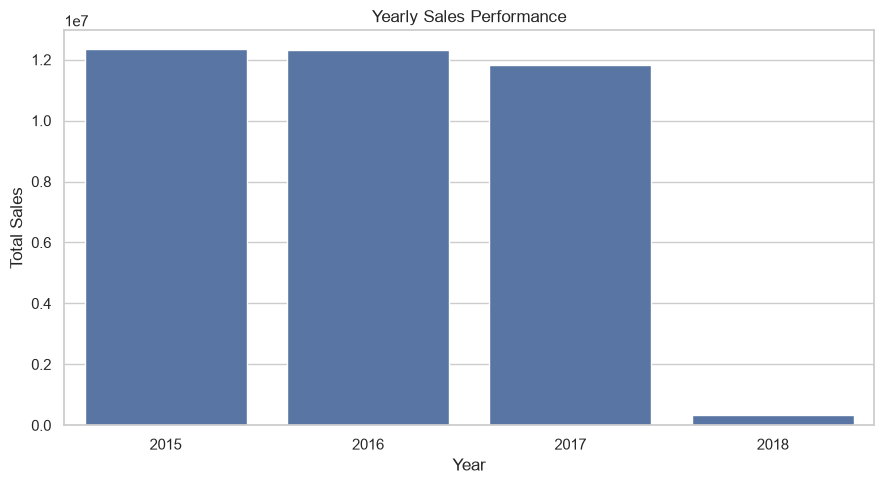

In [6]:
yearly_sales = (
    clean_df.groupby("Order_Year")["Sales"]
    .sum()
    .reset_index()
)

yearly_sales.columns = ["Year", "Total Sales"]

display(yearly_sales.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_sales,
    x="Year",
    y="Total Sales"
)

plt.title("Yearly Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

,Total_Sales,Total_Units,Order_Items
Category Name,,,
Fishing,6929653.69,17325,17325
Cleats,4431942.78,73734,24551
Camping & Hiking,4118425.57,13729,13729
Cardio Equipment,3694843.20,37587,12487
Women's Apparel,3147800.00,62956,21035
Water Sports,3113844.68,15540,15540
Men's Footwear,2891757.66,22246,22246
Indoor/Outdoor Games,2888993.91,57803,19298
Shop By Sport,1309522.04,32726,10984


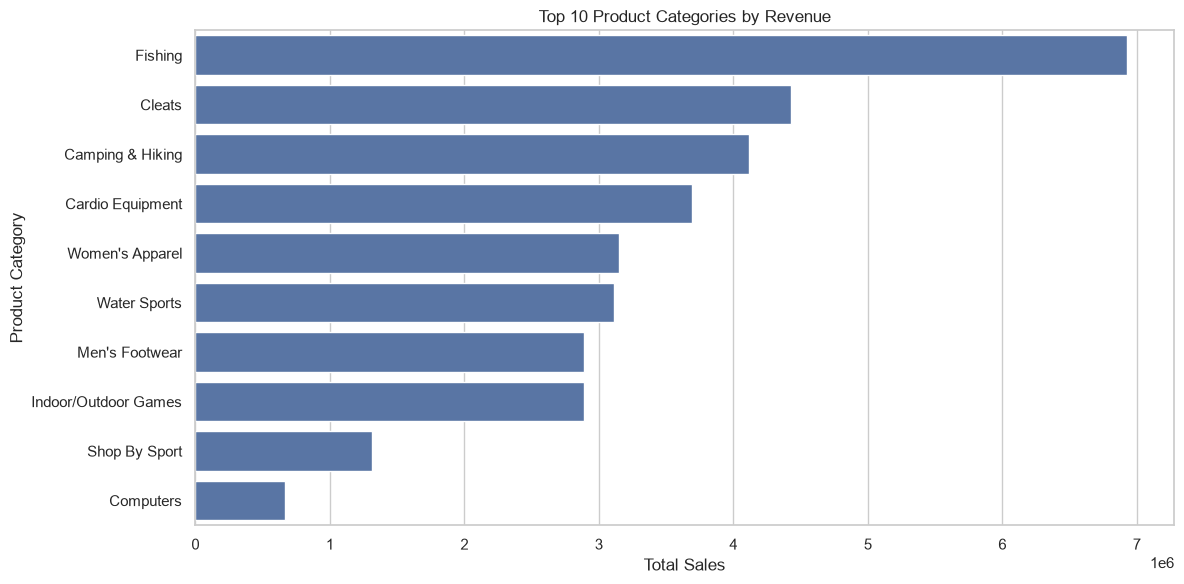

In [7]:
category_sales = (
    clean_df.groupby("Category Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Units=("Order Item Quantity", "sum"),
        Order_Items=("Order Item Id", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_sales.head(10).round(2))

top_categories = category_sales.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="Total_Sales",
    y="Category Name"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

,Total_Sales,Unique_Customers,Total_Order_Items
Customer Segment,,,
Consumer,19095790.16,10695,93504
Corporate,11168406.84,6239,54789
Home Office,6520538.02,3718,32226


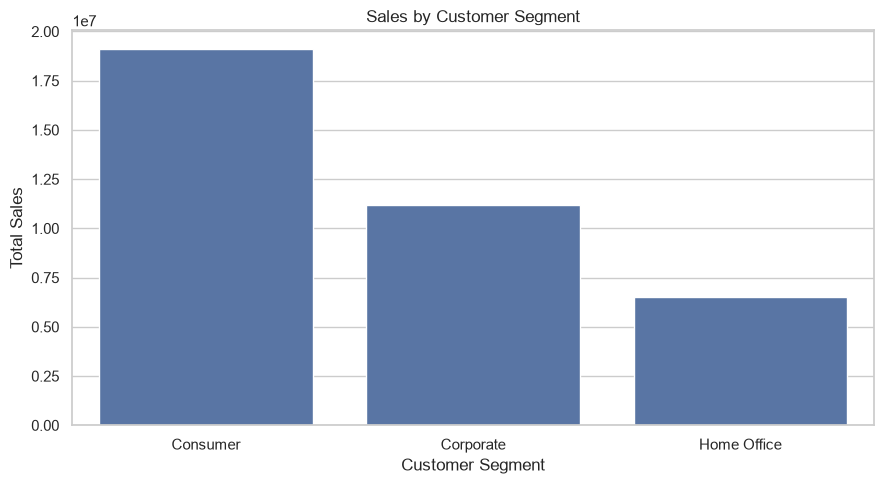

In [8]:
segment_analysis = (
    clean_df.groupby("Customer Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Unique_Customers=("Customer Id", "nunique"),
        Total_Order_Items=("Order Item Id", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(segment_analysis.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis.reset_index(),
    x="Customer Segment",
    y="Total_Sales"
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

,Total_Records,Unique_Orders,Percentage
Delivery Status,,,
Advance shipping,41592,15127,23.04
Late delivery,98977,36048,54.83
Shipping canceled,7754,2855,4.30
Shipping on time,32196,11722,17.84


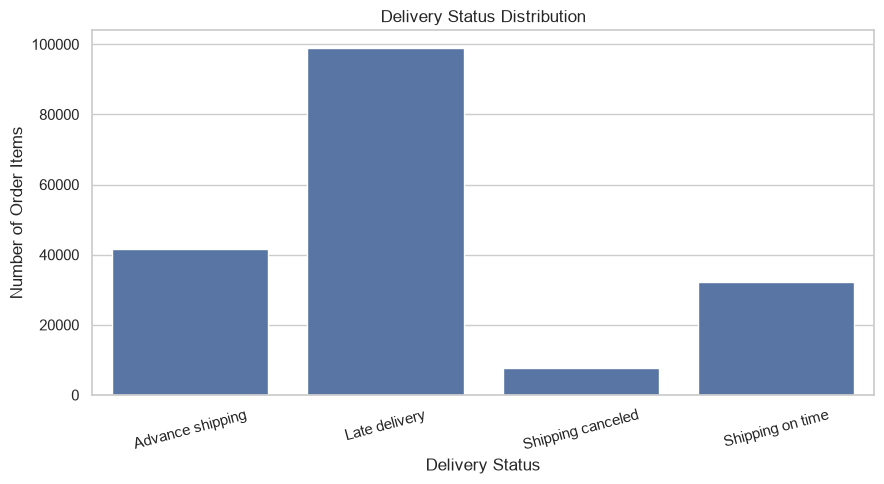

In [9]:
delivery_analysis = (
    clean_df.groupby("Delivery Status")
    .agg(
        Total_Records=("Order Item Id", "count"),
        Unique_Orders=("Order Id", "nunique")
    )
)

delivery_analysis["Percentage"] = (
    delivery_analysis["Total_Records"] /
    delivery_analysis["Total_Records"].sum() * 100
).round(2)

display(delivery_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=delivery_analysis.index,
    y=delivery_analysis["Total_Records"]
)

plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Order Items")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
shipping_analysis = (
    clean_df.groupby("Shipping Mode")
    .agg(
        Average_Actual_Days=("Days for shipping (real)", "mean"),
        Average_Scheduled_Days=("Days for shipment (scheduled)", "mean"),
        Late_Records=("Late_delivery_risk", "sum"),
        Total_Records=("Order Item Id", "count")
    )
)

shipping_analysis["Late_Percentage"] = (
    shipping_analysis["Late_Records"] /
    shipping_analysis["Total_Records"] * 100
)

display(shipping_analysis.round(2))

,Average_Actual_Days,Average_Scheduled_Days,Late_Records,Total_Records,Late_Percentage
Shipping Mode,,,,,
First Class,2.00,1.0,26513,27814,95.32
Same Day,0.48,0.0,4454,9737,45.74
Second Class,3.99,2.0,26987,35216,76.63
Standard Class,4.00,4.0,41023,107752,38.07


In [11]:
profit_analysis = (
    clean_df.groupby("Category Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Benefit=("Benefit per order", "sum"),
        Average_Benefit=("Benefit per order", "mean")
    )
    .sort_values("Total_Benefit", ascending=False)
)

profit_analysis["Benefit_Margin_Percentage"] = (
    profit_analysis["Total_Benefit"] /
    profit_analysis["Total_Sales"] * 100
)

display(profit_analysis.head(10).round(2))

,Total_Sales,Total_Benefit,Average_Benefit,Benefit_Margin_Percentage
Category Name,,,,
Fishing,6929653.69,756220.77,43.65,10.91
Cleats,4431942.78,494636.92,20.15,11.16
Camping & Hiking,4118425.57,427455.57,31.14,10.38
Cardio Equipment,3694843.20,383011.10,30.67,10.37
Women's Apparel,3147800.00,350421.03,16.66,11.13
Water Sports,3113844.68,325146.96,20.92,10.44
Indoor/Outdoor Games,2888993.91,318451.43,16.50,11.02
Men's Footwear,2891757.66,311902.82,14.02,10.79
Shop By Sport,1309522.04,129813.96,11.82,9.91


In [12]:
profit_analysis = (
    clean_df.groupby("Category Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Recorded_Benefit=("Benefit per order", "sum"),
        Average_Recorded_Benefit=("Benefit per order", "mean"),
        Order_Items=("Order Item Id", "nunique")
    )
    .sort_values("Total_Recorded_Benefit", ascending=False)
)

profit_analysis["Benefit_Margin_Percentage"] = (
    profit_analysis["Total_Recorded_Benefit"]
    / profit_analysis["Total_Sales"] * 100
)

display(profit_analysis.round(2))

,Total_Sales,Total_Recorded_Benefit,Average_Recorded_Benefit,Order_Items,Benefit_Margin_Percentage
Category Name,,,,,
Fishing,6929653.69,756220.77,43.65,17325,10.91
Cleats,4431942.78,494636.92,20.15,24551,11.16
Camping & Hiking,4118425.57,427455.57,31.14,13729,10.38
Cardio Equipment,3694843.20,383011.10,30.67,12487,10.37
Women's Apparel,3147800.00,350421.03,16.66,21035,11.13
Water Sports,3113844.68,325146.96,20.92,15540,10.44
Indoor/Outdoor Games,2888993.91,318451.43,16.50,19298,11.02
Men's Footwear,2891757.66,311902.82,14.02,22246,10.79
Shop By Sport,1309522.04,129813.96,11.82,10984,9.91


In [13]:
segment_delivery = (
    clean_df.groupby("Customer Segment")
    .agg(
        Total_Order_Items=("Order Item Id", "nunique"),
        Unique_Orders=("Order Id", "nunique"),
        Late_Items=("Late_delivery_risk", "sum")
    )
)

segment_delivery["Late_Percentage"] = (
    segment_delivery["Late_Items"]
    / segment_delivery["Total_Order_Items"] * 100
)

display(segment_delivery.round(2))

,Total_Order_Items,Unique_Orders,Late_Items,Late_Percentage
Customer Segment,,,,
Consumer,93504,34119,51248,54.81
Corporate,54789,19856,29982,54.72
Home Office,32226,11777,17747,55.07


In [14]:
region_delivery = (
    clean_df.groupby("Order Region")
    .agg(
        Total_Order_Items=("Order Item Id", "nunique"),
        Late_Items=("Late_delivery_risk", "sum"),
        Average_Shipping_Days=("Days for shipping (real)", "mean"),
        Average_Scheduled_Days=("Days for shipment (scheduled)", "mean")
    )
)

region_delivery["Late_Delivery_Percentage"] = (
    region_delivery["Late_Items"]
    / region_delivery["Total_Order_Items"] * 100
)

region_delivery = region_delivery.sort_values(
    "Late_Delivery_Percentage",
    ascending=False
)

display(region_delivery.round(2).head(10))

,Total_Order_Items,Late_Items,Average_Shipping_Days,Average_Scheduled_Days,Late_Delivery_Percentage
Order Region,,,,,
Central Africa,1677,972,3.56,2.92,57.96
South Asia,7731,4350,3.50,2.90,56.27
East Africa,1852,1036,3.51,2.94,55.94
Western Europe,27109,15140,3.50,2.90,55.85
South of USA,4045,2256,3.49,2.91,55.77
Eastern Europe,3920,2182,3.50,2.92,55.66
East of USA,6915,3849,3.50,2.92,55.66
Southeast Asia,9539,5297,3.50,2.94,55.53
Central Asia,553,306,3.42,2.77,55.33
